# Example: Compute the Probability of Profit and Exercise for a Call Contract
In this example, we'll compute the probability of profit (POP) for a __short__ call. If we sell a call, how likely are we to profit, and does Delta estimate the probability that the call is exercised?

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Calculate breakeven points for call option contracts:__ Compute the share price at expiration where a long or short call position switches between profit and loss.
> * __Project future share price distributions using two methods:__ Generate a log-normal distribution from risk-neutral GBM at the implied volatility, and build a Normal distribution from the implied volatility for quick estimates.
> * __Estimate probability of profit and probability of exercise:__ Evaluate the projected share price distribution at the breakeven price for the probability of profit and at the strike price for the probability of exercise. Compare the probability of exercise with Delta, and compare the risk-neutral probabilities with our forecast from historical parameters.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
Let's load an end-of-day options chain from the course archive, which holds the chains of 31 tickers captured after each close from April 13 to October 16, 2026. 

[The `MyOptionsEODChainDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyOptionsEODChainDataSet) returns the chain for one ticker, trading session, and expiration, with that session's share price. [The `filter(...)` function](https://dataframes.juliadata.org/stable/lib/functions/#Base.filter) keeps the target expiration, and we store the results in the `metadata::Dict{String,Any}` and `optionschain::DataFrame` variables.

In [2]:
ticker = "NVDA"; # underlying ticker: any of the 31 tickers in the archive except IWM, META, and MRNA, which have no historical parameters
quote_date = Date(2026, 10, 8); # trading session of the quotes
target_dte = 45; # days to expiration target, one of the archive's ladder values (2, 7, 14, 30, 45)

metadata, optionschain = let

    # initialize: the first call downloads the archive (about 112 MB) -
    session = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date); # every expiration that session

    # keep the expiration matched to the target -
    expiration = filter(:target_dte => ==(target_dte), session.data).expiration |> first;
    options_dataset = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date, expiration = expiration);
    metadata = options_dataset.metadata;
    optionschain = options_dataset.data;

    (metadata, optionschain) # return
end;

__Scenario:__ Suppose we sold the call with the strike price closest to some increment above the share price, among calls with a quoted implied volatility, found with [the `argmin(...)` function](https://docs.julialang.org/en/v1/base/collections/#Base.argmin). The premium is the mid quote, halfway between the bid and the ask. We store the contract in the `contract::DataFrameRow` variable:

In [3]:
contract = let

    # initialize -
    share_price_multiplier = 1.03; # 3% above the share price
    Sₒ = metadata["underlying_close"]; # share price at the close of the quote date (USD/share)
    calls = filter(row -> row.type == "call" && !ismissing(row.implied_vol), optionschain);

    # the strike closest to 3% above the share price -
    i = argmin(abs.(calls.strike .- share_price_multiplier*Sₒ));
    calls[i, :] # return
end;

Which contract did we sell? [The `select(...)` function](https://dataframes.juliadata.org/stable/lib/functions/#DataFrames.select) keeps the columns we use:

In [4]:
select(DataFrame(contract), :type, :strike, :bid, :ask, :mid, :implied_vol, :delta) # the columns we use; the chain has 19

Row,type,strike,bid,ask,mid,implied_vol,delta
,String,Float64,Float64,Float64,Float64,Float64?,Float64?
1,call,235.0,9.79,9.97,9.88,0.3543,0.4833


Next, let's load the GBM parameters estimated from the 2014 to 2024 training data in the parameter-estimation example, saved in [`SAGBM-Parameters-Fall-2025.csv`](data/SAGBM-Parameters-Fall-2025.csv). 

The `drift` column contains the mean growth rate estimate $\hat{\mu}_{g}$, and the `volatility` column contains $\hat{\sigma}$. We store the table in the `parameters_df::DataFrame` variable:

In [5]:
parameters_df = let

    # load the saved 2014–2024 estimates: the drift column is the mean growth rate μ̂_g -
    df = CSV.read(joinpath(_PATH_TO_DATA, "SAGBM-Parameters-Fall-2025.csv"), DataFrame);

    # checks -
    @assert count(==(metadata["ticker"]), df.ticker) == 1 "no 2014–2024 parameters for $(metadata["ticker"]); choose another ticker"

    df # return
end;

### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, permissible values, etc. 

In [6]:
Sₒ = metadata["underlying_close"]; # share price at the close of the quote date (USD/share)
DTE = metadata["DTE"]; # days to expiration (days)
Δt = (1/365); # one calendar day, expressed in years
T = DTE*Δt; # time to expiration (years)
K = contract.strike; # strike price of the call (USD/share)
P = contract.mid; # premium: the mid quote (USD/share)
IV = contract.implied_vol; # implied volatility (decimal, 1/sqrt(year))
Δ_quote = contract.delta; # the archive's Delta for this call (USD/share per USD/share)
ticker_parameters = only(eachrow(filter(:ticker => ==(metadata["ticker"]), parameters_df))); # this ticker's 2014–2024 estimates
# μ̂_g and σ̂ are rates per year. The training data has about 252 trading days per calendar year,
# so they apply directly to T measured in calendar years (DTE/365).
μ̂_g = ticker_parameters.drift; # mean growth rate (1/yr)
σ̂ = ticker_parameters.volatility; # historical volatility (1/sqrt(year))
μ̂ = μ̂_g + σ̂^2/2; # GBM drift of our forecast (1/yr)
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-08 (0.0418 on 2026-10-16), U.S. Treasury Daily Treasury Bill Rates (accessed 2026-10-19); update it if you change quote_date
# https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_bill_rates&field_tdr_date_value_month=202610
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)
𝒟 = exp(gᵧ*T); # accumulation factor from today to expiration (dimensionless)

Let's collect (and display) these inputs in one table with [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table):

In [7]:
let
    # the inputs every calculation in this notebook shares -
    df = DataFrame(
        quantity = ["ticker", "quote date", "expiration", "days to expiration", "share price Sₒ", "strike price K",
            "premium P (mid quote)", "implied volatility", "Delta (archive quote)", "time to expiration T", "risk-free rate gᵧ",
            "mean growth rate μ̂_g", "historical volatility σ̂", "GBM drift μ̂ (our forecast)"],
        value    = Any[ticker, metadata["quote_date"], metadata["expiration_date"], DTE, Sₒ, K,
            P, IV, Δ_quote, round(T, digits = 4), round(gᵧ, digits = 4),
            round(μ̂_g, digits = 4), round(σ̂, digits = 4), round(μ̂, digits = 4)],
        units    = ["", "", "", "days", "USD/share", "USD/share", "USD/share", "1/sqrt(year)", "", "years", "1/year", "1/year", "1/sqrt(year)", "1/year"]
    );
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 ---------------------------- ------------ --------------
  quantity                          value   units        
 ---------------------------- ------------ --------------
  ticker                             NVDA
  quote date                   2026-10-08
  expiration                   2026-11-20
  days to expiration                   43   days
  share price Sₒ                   230.57   USD/share
  strike price K                    235.0   USD/share
  premium P (mid quote)              9.88   USD/share
  implied volatility               0.3543   1/sqrt(year)
  Delta (archive quote)            0.4833
  time to expiration T             0.1178   years
  risk-free rate gᵧ                0.0413   1/year
  mean growth rate μ̂_g             0.5033   1/year
  historical volatility σ̂          0.3886   1/sqrt(year)
  GBM drift μ̂ (our forecast)       0.5788   1/year
 ---------------------------- ------------ --------------


Next, we build the call's contract model, an instance of [the `MyAmericanCallContractModel` type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanCallContractModel), with [the `build(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}). 

Its [NamedTuple](https://docs.julialang.org/en/v1/base/base/#Core.NamedTuple) argument sets the strike price, the premium, the time to expiration in years (the `DTE` field), the position (`sense = 1`, long), the number of contracts (`copy`), and the decimal implied volatility. We save the model in the `call_option_model::MyAmericanCallContractModel` variable:

In [8]:
call_option_model = build(MyAmericanCallContractModel, (
    K = K, # strike price
    premium = P, # mid quote
    DTE = T, # time to expiration (years)
    sense = 1, # long contract, we also price/compute long and convert to short
    copy = 1, # one contract
    IV = IV # implied volatility, must be a decimal
));

___

## Task 1: Compute the breakeven points for long and short calls
In this task, we'll compute the breakeven price of our short call contract. The breakeven $S^{\ddagger}$ is the share price at expiration where the profit is zero for both the buyer and the seller. The premium is paid today, so the profit carries it to expiration with the accumulation factor $\mathcal{D}_{T,0}(g_{y})=e^{g_{y}T}$.

For our call, the breakeven share price (USD/share) is:
$$
\begin{align*}
S^{\ddagger} &= K + \mathcal{D}_{T,0}(g_{y})\cdot\mathcal{P}_{c}(K,S(0))
\end{align*}
$$
The buyer profits when the share price at expiration is above $S^{\ddagger}$, and the seller profits when it is below.

`Unhide` the code block below to see how we plotted the profit at expiration of the long and short call with [the `payoff(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.payoff) and [the `plot(...)` function](https://docs.juliaplots.org/stable/api/#RecipesBase.plot):

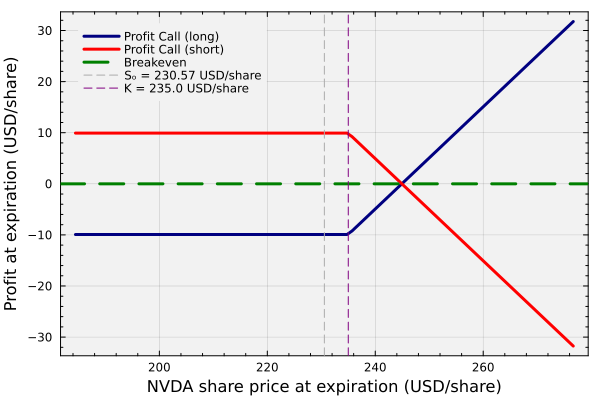

In [9]:
let
    N = 100; # how many points do we want?
    β = range(0.8,stop=1.2, length=N) |> collect;
    ST = Sₒ.*β; # future share price at expiration
    θ = -1; # we are in the short position

    # compute the payoff of the contract -
    payoff_array_long = payoff([call_option_model], ST); # this is always computed for a LONG contract
    profit_array_long = payoff_array_long[:,3] .- 𝒟*P; # premium carried to expiration
    profit_array_short = θ*(payoff_array_long[:,3] .- 𝒟*P);

    # let's visualize
    plot(payoff_array_long[:,1], profit_array_long, c=:navy, lw=3, label="Profit Call (long)", legend=:topleft)
    plot!(payoff_array_long[:,1], profit_array_short, c=:red, lw=3, label="Profit Call (short)")
    hline!([0.0], c=:green, lw=3, ls=:dash, label="Breakeven")
    vline!([Sₒ], lw=1, c=:gray67, ls=:dash, label="Sₒ = $(Sₒ) USD/share")
    vline!([K], lw=1, c=:purple, ls=:dash, label="K = $(K) USD/share")
    xlabel!("$(ticker) share price at expiration (USD/share)", fontsize=18)
    ylabel!("Profit at expiration (USD/share)", fontsize=18)
    plot!(bg="gray95", background_color_outside="white", framestyle = :box, 
        fg_legend = :transparent, xminorticks = true, yminorticks = true);
end

Let's compute the breakeven price and store it in the `computed_breakeven_price::Float64` variable:

In [10]:
computed_breakeven_price = K + 𝒟*P # breakeven share price S‡ (USD/share)

244.92817260627905

### Check: Is the profit zero at the computed breakeven?
At $S(T) = S^{\ddagger}$, the buyer's and the seller's profit should both be zero. Let's compute both with [the `profit(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.profit), passing the accumulation factor `𝒟` and a seller's contract model with `sense = -1`. We confirm the result with [the `@assert` macro](https://docs.julialang.org/en/v1/base/base/#Base.@assert) and [the `isapprox(...)` function](https://docs.julialang.org/en/v1/base/math/#Base.isapprox).

> __Test:__ If either profit at the `computed_breakeven_price` is _not_ approximately zero, an [AssertionError](https://docs.julialang.org/en/v1/base/base/#Core.AssertionError) is thrown.

So what do we get?

In [11]:
let
    # initialize: the seller's contract model -
    short_call_model = build(MyAmericanCallContractModel, (K = K, premium = P, DTE = T, sense = -1, copy = 1, IV = IV));

    # profit at the breakeven (USD/share), premium carried to expiration: column 2 is the buyer, column 3 the seller -
    profit_array = profit([call_option_model, short_call_model], [computed_breakeven_price]; 𝒟 = 𝒟);

    # one contract: 100 shares per contract -
    df = DataFrame(
        quantity = ["breakeven price S‡", "premium the seller receives for one contract",
            "buyer's profit at S‡", "seller's profit at S‡"],
        value    = [computed_breakeven_price, 100*P, round(profit_array[1,2], digits = 8) + 0.0, round(profit_array[1,3], digits = 8) + 0.0], # + 0.0 prints -0.0 as 0.0
        units    = ["USD/share", "USD", "USD/share", "USD/share"]
    );

    # make a pretty table - I love pretty tables!
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        formatters = [fmt__printf("%.2f", [2])],
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks -
    @assert isapprox(profit_array[1,2], 0.0; atol = 1e-10) "the buyer's profit is not zero at the breakeven"
    @assert isapprox(profit_array[1,3], 0.0; atol = 1e-10) "the seller's profit is not zero at the breakeven"
end

 ---------------------------------------------- -------- -----------
  quantity                                        value   units     
 ---------------------------------------------- -------- -----------
  breakeven price S‡                             244.93   USD/share
  premium the seller receives for one contract   988.00   USD
  buyer's profit at S‡                             0.00   USD/share
  seller's profit at S‡                            0.00   USD/share
 ---------------------------------------------- -------- -----------


___

## Task 2: Construct a single asset GBM model of the share price
In this task, we'll use geometric Brownian motion to compute the distribution of the share price at expiration $S(T)$. Despite a few shortcomings, geometric Brownian motion has a convenient analytical solution:
$$
\begin{equation*}
S_{t} = S_{0}\;\exp\Biggl[\left(\mu-\frac{\sigma^{2}}{2}\right)\left(t - t_{0}\right) + (\sigma\sqrt{t-t_{0}})\;{Z_{t}(0,1)}\Biggr]
\end{equation*}
$$
where $S_{0}$ is the share price at $t_{0}$, and $Z_{t}(0,1)$ is a standard normal random variable. The future share price is log-normally distributed, with expectation and variance:
$$
\begin{align*}
\mathbb{E}\left(S_{t}\right) &= S_{0}\;\exp\left(\mu(t-t_{0})\right)\\
\text{Var}\left(S_{t}\right) &= S_{0}^{2}e^{2\mu\cdot(t-t_{0})}\left[e^{\sigma^{2}(t-t_{0})} - 1\right]
\end{align*}
$$
where $t-t_{0}$ is the time interval. We'll use the analytical solution at $t = T$, the contract's expiration. Next, we build [a `MyGeometricBrownianMotionEquityModel` instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel) with [the `build(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.build-Tuple{Type{MyGeometricBrownianMotionEquityModel},%20NamedTuple}). 

We set the drift `μ` to the risk-free rate $g_{y}$ and the volatility `σ` to the implied volatility. The probabilities we compute are then under $\mathbb{Q}$, the probabilities inside the market price, not our forecast. We save the model in the `model::MyGeometricBrownianMotionEquityModel` variable:

In [12]:
model = build(MyGeometricBrownianMotionEquityModel, (
    μ = gᵧ, # risk-neutral drift: let's mess with this ...
    σ = IV  # implied volatility of the contract
)); # this model is risk-neutral.

Let's generate share prices from $T_{1} = 0$ to $T_{2} = T$ in daily steps with [the `sample(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyGeometricBrownianMotionEquityModel,%20NamedTuple}). 

This function returns one row per date and one column per path, with the time in column 1. We keep columns `2:end` of the last row with [the pipe operator](https://docs.julialang.org/en/v1/manual/functions/#Function-composition-and-piping) and store them in the `endpoint_samples::Array{Float64,1}` variable. We fix the random seed, so the samples repeat. 

So what do we get?

In [13]:
endpoint_samples = let

    # initialize
    Random.seed!(5660); # reproducible samples
    number_of_samples = 50000; # how many samples do we want to generate?

    # compute the endpoint samples -
    endpoint = VLQuantitativeFinancePackage.sample(model, (
        T₁ = 0.0, # start time (years)
        T₂ = T, # end time (years)
        Δt = Δt, # time step (years)
        Sₒ = Sₒ # initial share price (USD/share)
    ), number_of_paths = number_of_samples) |> samples -> samples[end,2:end]; # get last row from col 2 -> number_of_paths

    endpoint; # return
end;

In [25]:
endpoint_samples

50000-element Vector{Float64}:
 239.26807323883853
 236.19503612782032
 211.20018198738762
 274.06079148499265
 211.9060559656463
 222.777114648386
 196.880961400135
 200.06413681750075
 278.46659227626185
 222.0817889385176
   ⋮
 172.57968702372193
 215.02460473584026
 201.95892607989677
 248.4917121955061
 242.61163799788608
 206.82248092490332
 160.29712707734933
 274.8196809001224
 197.7060250417657

### Check: Are future GBM share prices log-normally distributed?
Geometric Brownian motion should generate __log-normally distributed__ share prices, so the logarithm of the share price at expiration is normally distributed:
$$
\begin{equation*}
\ln S(T) \sim \mathcal{N}\left(\ln S_{0} + \left(\mu-\frac{\sigma^{2}}{2}\right)T,~\sigma^{2}T\right)
\end{equation*}
$$
Let's save this [`LogNormal` distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.LogNormal) in the `d_gbm::LogNormal{Float64}` variable. Its two arguments are the mean and the standard deviation of $\ln S(T)$:

In [14]:
d_gbm = LogNormal(log(Sₒ) + (model.μ - model.σ^2/2)*T, model.σ*sqrt(T));

Next, we check the samples against `d_gbm` with an [exact one-sample Kolmogorov-Smirnov test](https://juliastats.org/HypothesisTests.jl/stable/nonparametric/#HypothesisTests.ExactOneSampleKSTest) and store it in the `test_result::ExactOneSampleKSTest` variable.
> __Hypothesis:__ The null hypothesis `H0` is that the `endpoint_samples` come from `d_gbm`. The alternative `H1` is that they do not.

We reject `H0` if the test's [p-value](https://en.wikipedia.org/wiki/P-value) is _less than_ a cutoff, here `0.01`.

In [15]:
test_result = ExactOneSampleKSTest(endpoint_samples, d_gbm)

Exact one sample Kolmogorov-Smirnov test
----------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.00287703

Test summary:
    outcome with 95% confidence: fail to reject h_0
    two-sided p-value:           0.8023

Details:
    number of observations:   50000


In [16]:
# checks -
@assert test_result |> pvalue > 0.01 # if this passes, then S(T) ~ d_gbm

`Unhide` the code block below to see how we plotted the simulated share prices at expiration against `d_gbm`.

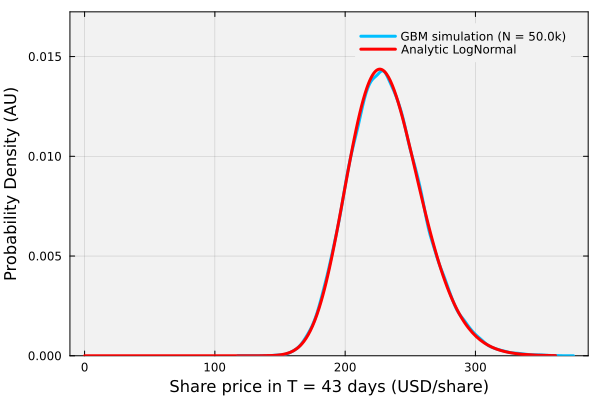

In [17]:
let
    density(endpoint_samples, lw=3, c=:deepskyblue1, label="GBM simulation (N = $(length(endpoint_samples)/1000)k)")
    plot!(d_gbm, lw=3, label="Analytic LogNormal", c=:red, 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent,
        ylims = (0, 1.2*pdf(d_gbm, mode(d_gbm)))) # keep the peak inside the frame
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
end

### Alternative: Future share price projection using implied volatility
A quicker estimate uses the __implied volatility__ directly: a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal) $\mathcal{N}(\mu_{IV},\sigma_{IV})$ with mean $\mu_{IV} = S_{0}\exp(g_{y}T)$, the risk-neutral future value of today's share price. Its standard deviation is:
$$
\sigma_{IV} = S_{0}\cdot\text{IV}\cdot\sqrt{T}
$$
where the implied volatility IV is a decimal and $T$ is in years.

> __Watch out!__ A Normal distribution can produce negative share prices. A [truncated Normal distribution](https://juliastats.org/Distributions.jl/stable/truncate/#Truncated-Distributions) avoids this.

Despite this issue, the model is __widely__ used for quick estimates of share price ranges from the forward-looking implied volatility. Let's save it in the `d_IV::Normal{Float64}` variable:

In [18]:
d_IV = Normal(Sₒ*exp(gᵧ*T), Sₒ*IV*sqrt(T));

`Unhide` the code block below to see how we plotted the `d_gbm` and `d_IV` densities at expiration.

> __What do we see?__ The log-normal `d_gbm` (blue line) is right-skewed and has no negative share prices. The Normal `d_IV` (red line) is symmetric around $\mu_{IV}$ and puts a small probability on negative share prices.

How do the two distributions compare?

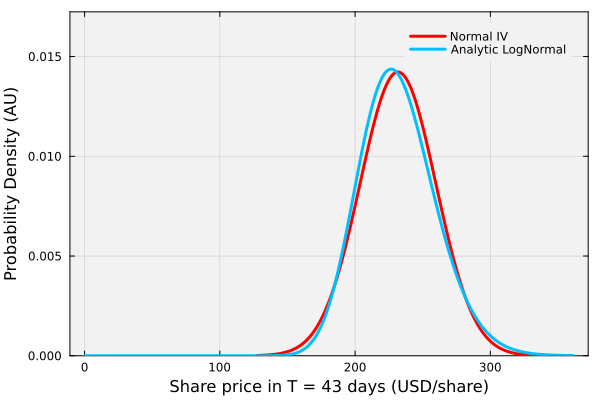

In [19]:
let
    plot(d_IV, lw=3, label="Normal IV", c=:red, 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent)
    plot!(d_gbm, lw=3, label="Analytic LogNormal", c=:deepskyblue1,
        ylims = (0, 1.2*max(pdf(d_gbm, mode(d_gbm)), pdf(d_IV, mean(d_IV))))) # keep the peaks inside the frame
    
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
end

___

## Task 3: Estimate the probability of profit and exercise for our call contract
In this task, we estimate the probability of profit and the probability of exercise of our call, then compare the probability of exercise with Delta. Finally, we recompute both probabilities with our forecast from historical parameters.

> __Probability of Profit (POP)__
>
> The probability of profit follows from the [cumulative distribution function](https://en.wikipedia.org/wiki/Cumulative_distribution_function) $F_{S}$ of the projected share price at expiration, evaluated at the breakeven price $S^{\ddagger}$:
> * __Buyer's perspective__: the long call is profitable when $S(T) > S^{\ddagger}$, so $\text{POP} = 1 - F_{S}(S^{\ddagger})$.
> * __Seller's perspective__: the short call is profitable when $S(T)\leq S^{\ddagger}$, so $\text{POP} = F_{S}(S^{\ddagger})$.
>
> [The `cdf(...)` function](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.cdf-Tuple{UnivariateDistribution,%20Real}) evaluates $F_{S}$ for `d_gbm` and `d_IV`. For the simulated samples, the probability of profit is the fraction of samples on the profitable side of $S^{\ddagger}$.

### Probability of profit (POP) table
`Unhide` the code block below to see how we built the table.
> __Hypothesis:__ The samples and `d_gbm` come from the same model, so their probabilities of profit should agree within sampling error. Do they? How far off is `d_IV`?

So what are the results?

In [20]:
let 

    # initialize -
    B = computed_breakeven_price;
    number_of_samples = length(endpoint_samples);
    seller_POP_samples = count(endpoint_samples .≤ B)/number_of_samples; # fraction of samples at or below the breakeven

    # one row per perspective -
    table_df = DataFrame(
        perspective = ["buyer", "seller"],
        event = ["S(T) > S‡", "S(T) ≤ S‡"],
        GBM_samples = [1 - seller_POP_samples, seller_POP_samples],
        GBM_analytic = [1 - cdf(d_gbm, B), cdf(d_gbm, B)],
        normal_IV = [1 - cdf(d_IV, B), cdf(d_IV, B)]
    );
    pretty_table(table_df; column_labels = ["perspective", "profitable when", "GBM samples", "d_gbm", "d_IV"],
        formatters = [fmt__printf("%.4f", [3, 4, 5])],
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the samples agree with d_gbm to within five standard errors -
    standard_error = sqrt(cdf(d_gbm, B)*(1 - cdf(d_gbm, B))/number_of_samples);
    @assert abs(seller_POP_samples - cdf(d_gbm, B)) ≤ 5*standard_error "the simulated POP disagrees with d_gbm"
end

 ------------- ----------------- ------------- -------- --------
  perspective   profitable when   GBM samples    d_gbm     d_IV 
 ------------- ----------------- ------------- -------- --------
        buyer         S(T) > S‡        0.3037   0.3024   0.3185
       seller         S(T) ≤ S‡        0.6963   0.6976   0.6815
 ------------- ----------------- ------------- -------- --------


### Probability of exercise and Delta
Delta measures the change in the premium for a `+1 USD/share` change in the share price. One of its secret lives is its connection with the probability of exercise.

> __Probability of Being In-the-Money (ITM)__: The absolute value of Delta is often used to estimate the probability that an option expires ITM, so a Delta of 0.40 suggests a 40% chance. An option that finishes ITM is exercised for its intrinsic value, and one that finishes out of the money expires worthless.

The archive quotes Delta for every contract, and we stored it in the `Δ_quote` variable.

__From the buyer's perspective:__ The call is exercised when the share price ends at least one cent above the strike price, $S(T) > K+\epsilon$ with $\epsilon=$ `0.01` USD/share. We store the probability of exercise, $\text{POE} = 1 - F_{S}(K+\epsilon)$, in the `POE::Float64` variable:

In [21]:
POE = 1 - cdf(d_gbm, K + (1/100)) # buyer's perspective

0.4294980151598192

__From the seller's perspective:__ The seller wants the call to expire out of the money, $S(T) \leq K$, and keep the whole premium. We store the probability of this case, $F_{S}(K)$, in the `P_OTM::Float64` variable:

In [22]:
P_OTM = cdf(d_gbm, K) # seller's perspective

0.5703645698019986

__The secret life of Delta:__ If Delta is the probability of finishing ITM, then $1-\Delta$ is the probability of the outcome the seller wants. Take a CRR tree with $h$ steps of length $\Delta t=T/h$ (`Δt_tree` in the code), up factor $u$, and risk-neutral up probability $q$.

With no dividends, a call's Delta on this tree is exactly a probability of exercise, computed with $q^{*}=q\,u\,e^{-g_{y}\Delta t}$ in place of $q$:
$$
\Delta_{c} = \sum_{k\,\in\,\text{ITM}}\binom{h}{k}\left(q^{*}\right)^{k}\left(1-q^{*}\right)^{h-k}
$$
where $k$ is the number of up moves and ITM is the set of terminal nodes above the strike. The risk-neutral probability of exercise is the same sum with the up probability $q$:
$$
\mathbb{Q}\left(S(T)>K\right) = \sum_{k\,\in\,\text{ITM}}\binom{h}{k}q^{k}(1-q)^{h-k}
$$
Each sum is the [Binomial distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Binomial) probability of at least $k_{\min}$ up moves, the fewest that finish in the money. The Leisen–Reimer tree in the [Greeks example](CHEME-5660-L10a-Example-Greeks-PutCall-Fall-2026.ipynb) has the same structure, so its Delta is also a sum with $q^{*}$.

Let's build the tree at the implied volatility and compare these sums with the quoted Delta and the POE from `d_gbm`. We also check that the $q^{*}$ sum is the slope of the tree premium from [the `binomial_premium(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.binomial_premium):

In [23]:
let

    # initialize: a CRR tree at the implied volatility -
    h = 10_000; # number of tree steps: the tree sums swing by about ±0.003 as h changes by one
    Δt_tree = T/h; # length of one tree step (years)
    u = exp(IV*sqrt(Δt_tree)); # up factor
    d = 1/u; # down factor
    q = (exp(gᵧ*Δt_tree) - d)/(u - d); # risk-neutral up probability
    q_star = q*u*exp(-gᵧ*Δt_tree); # the up probability q* behind Delta

    # the fewest up moves k_min that finish in the money, Sₒuᵏdʰ⁻ᵏ > K -
    k_min = 0;
    while Sₒ*u^k_min*d^(h - k_min) ≤ K
        k_min += 1;
    end

    # each sum is the probability of at least k_min up moves in h steps -
    POE_tree = 1 - cdf(Binomial(h, q), k_min - 1); # up probability q
    Δ_tree = 1 - cdf(Binomial(h, q_star), k_min - 1); # up probability q*
    POE_samples = count(endpoint_samples .> K + (1/100))/length(endpoint_samples);

    # compare -
    df = DataFrame(
        quantity = ["Delta (archive quote)", "Delta, CRR tree", "POE, GBM samples", "POE, d_gbm",
            "POE, CRR tree", "1 - Delta (archive quote)", "P(OTM), d_gbm"],
        value    = [Δ_quote, Δ_tree, POE_samples, POE, POE_tree, 1 - Δ_quote, P_OTM],
        formula  = ["Δ", "sum over ITM nodes with q*", "fraction of samples with S(T) > K + ε", "1 - F_S(K + ε)",
            "sum over ITM nodes with q", "1 - Δ", "F_S(K)"]
    );
    pretty_table(df; column_labels = ["quantity", "value", "lecture formula"], alignment = [:l, :r, :l],
        formatters = [fmt__printf("%.4f", [2])],
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the q* sum is the slope of the tree premium (central difference with a tiny step) -
    δS = 0.001; # share price step for the central difference (USD/share)
    Δ_slope = (binomial_premium(call_option_model; method = :crr, h = h, Sₒ = Sₒ + δS, σ = IV, T = T, μ = gᵧ) -
        binomial_premium(call_option_model; method = :crr, h = h, Sₒ = Sₒ - δS, σ = IV, T = T, μ = gᵧ))/(2*δS);
    @assert isapprox(Δ_tree, Δ_slope; atol = 1e-6) "the q* sum is not the slope of the tree premium"
    @assert q_star > q "q* is not larger than q"

    # checks: the tree POE is within one terminal node's probability of the d_gbm POE, and the quoted Delta exceeds it -
    @assert abs(POE_tree - POE) < pdf(Binomial(h, q), k_min) "the tree POE is far from the d_gbm POE"
    @assert Δ_quote > POE "the quoted Delta does not exceed the POE"
end

 --------------------------- -------- ---------------------------------------
  quantity                     value   lecture formula                       
 --------------------------- -------- ---------------------------------------
  Delta (archive quote)       0.4833   Δ
  Delta, CRR tree             0.4804   sum over ITM nodes with q*
  POE, GBM samples            0.4312   fraction of samples with S(T) > K + ε
  POE, d_gbm                  0.4295   1 - F_S(K + ε)
  POE, CRR tree               0.4322   sum over ITM nodes with q
  1 - Delta (archive quote)   0.5167   1 - Δ
  P(OTM), d_gbm               0.5704   F_S(K)
 --------------------------- -------- ---------------------------------------


> __So is Δ ≈ POE?__ The quoted Delta sits close to the tree's sum with $q^{*}$. The `d_gbm` POE sits close to the tree's sum with $q$. Because $q^{*}>q$, Delta overstates the risk-neutral POE, and the gap grows with $\sigma\sqrt{T}$.

### Probabilities under our belief
So far, we computed the probabilities under $\mathbb{Q}$, the probabilities inside the market price, with drift $g_{y}$ and the implied volatility. The lecture computes the POE and POP under our belief $\mathbb{P}$, here GBM with the historical drift $\hat{\mu}=\hat{\mu}_{g}+\hat{\sigma}^{2}/2$ and volatility $\hat{\sigma}$.

Let's compute the POE and the seller's POP for four drift and volatility pairs:
* __Our belief $\mathbb{P}$:__ drift $\hat{\mu}$ and volatility $\hat{\sigma}$.
* __Historical drift, implied volatility:__ drift $\hat{\mu}$ and the implied volatility.
* __Risk-neutral $\mathbb{Q}$:__ drift $g_{y}$ and the implied volatility, the case above.
* __Risk-free drift, historical volatility:__ drift $g_{y}$ and volatility $\hat{\sigma}$.

Each pair gives a log-normal share price at expiration, as in Task 2. The two mixed pairs change one input at a time, so we can see how the drift and the volatility each move the probabilities. So what do we get?

In [24]:
let

    # initialize: the four drift and volatility pairs -
    B = computed_breakeven_price;
    cases = [
        ("our belief ℙ", μ̂, σ̂),
        ("historical drift, implied volatility", μ̂, IV),
        ("risk-neutral ℚ", gᵧ, IV),
        ("risk-free drift, historical volatility", gᵧ, σ̂)
    ];

    # each pair gives a log-normal share price at expiration -
    df = DataFrame(case = String[], drift = Float64[], volatility = Float64[], POE = Float64[], seller_POP = Float64[]);
    for (label, μ, σ) in cases
        d = LogNormal(log(Sₒ) + (μ - σ^2/2)*T, σ*sqrt(T)); # distribution of S(T)
        push!(df, (label, μ, σ, 1 - cdf(d, K + (1/100)), cdf(d, B))); # POE at K + ε, seller's POP at S‡
    end
    pretty_table(df; column_labels = ["case", "GBM drift (1/yr)", "volatility (1/sqrt(yr))", "POE", "seller's POP"],
        alignment = [:l, :r, :r, :r, :r], formatters = [fmt__printf("%.4f", [2, 3, 4, 5])],
        table_format = TextTableFormat(borders = text_table_borders__compact),
        fit_table_in_display_horizontally = false);
    println("Delta (archive quote): $(round(Δ_quote, digits = 4))");

    # checks: the ℚ row is the d_gbm distribution from Task 2 -
    @assert isapprox(df.POE[3], POE; atol = 1e-12) "the ℚ row does not match the POE from d_gbm"
    @assert isapprox(df.seller_POP[3], cdf(d_gbm, B); atol = 1e-12) "the ℚ row does not match the seller's POP from d_gbm"
end

 ---------------------------------------- ------------------ ------------------------- -------- --------------
  case                                     GBM drift (1/yr)   volatility (1/sqrt(yr))      POE   seller's POP 
 ---------------------------------------- ------------------ ------------------------- -------- --------------
  our belief ℙ                                       0.5788                    0.3886   0.6185         0.5034
  historical drift, implied volatility               0.5788                    0.3543   0.6342         0.4988
  risk-neutral ℚ                                     0.0413                    0.3543   0.4295         0.6976
  risk-free drift, historical volatility             0.0413                    0.3886   0.4312         0.6855
 ---------------------------------------- ------------------ ------------------------- -------- --------------
Delta (archive quote): 0.4833


> __What do we see?__
>
> * __The drift:__ Compare rows with the same volatility. A larger drift moves probability toward higher share prices, which raises the POE and lowers the seller's POP.
> * __The volatility:__ Compare rows with the same drift. The difference shows how much the volatility matters for this contract. It is small when the historical volatility is close to the implied volatility.
> * __Delta is not our forecast:__ The tree sums showed that Delta sits above the risk-neutral POE. Under our belief, the POE can sit above or below Delta, as the lecture points out. The line under the table gives Delta for comparison.

The historical estimates come from 2014 to 2024 prices. Our forecast assumes the share price keeps that growth rate and volatility until expiration.
___

## Summary
In this example, we computed the probability of profit for a short call from its breakeven price and projected share price distributions. We then computed the probability of exercise at the strike price and compared it with Delta. Finally, we recomputed both probabilities with historical parameters.

> __Key Takeaways:__
>
> * __Breakeven price determines profitability boundaries:__ For a call, the breakeven price is the strike price plus the premium carried to expiration. The seller profits when the share price at expiration ends below it, and the buyer profits when it ends above.
> * __Two methods project future share price distributions:__ We projected the share price at expiration with risk-neutral GBM, which gives a log-normal distribution, and with a Normal distribution built from the implied volatility. The Normal estimate was close but put a small probability on negative share prices.
> * __Probability of profit and probability of exercise use different reference points:__ The probability of profit reads the projected distribution at the breakeven price, and the probability of exercise reads it at the strike price. Delta was close to, but larger than, the risk-neutral probability of exercise, and under our historical forecast the probability of exercise can sit above or below Delta.

Together, the breakeven price and the projected distribution tell us how likely a call position is to pay off and to be exercised.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___